# Whole-cell structure and node interaction analysis
Saved 10-node GT and MPNN + ResNet checkpoints, fold 0, evaluated without retraining. A mean + ResNet model is the invariant control.

Primary results exclude cells lacking nucleus coordinates; the original cache excludes nodes within **5 µm Euclidean distance of the nucleus**. This is the original eight-class taxonomy, not the newer six-class morpho taxonomy. The strict cohort has seven supported classes; oligodendrocytes are absent. The historical cohort remains available separately. These held-out cells also served for checkpoint selection, so this is not an independent final test set.

Dense Q/K/V projections mix feature dimensions within nodes. Attention mixes values across nodes. `nodewise_mean_readout` disables updates to ordinary nodes but lets CLS uniformly pool their values; `uniform_attention` retains node mixing with equal weights. `no_attention_update` also disables CLS information collection and is a deliberately degenerate diagnostic, not a fair nodewise baseline.

These inference interventions measure reliance of the trained model, not the performance of a separately trained ablated architecture. Activation magnitudes describe computation; they do not establish causal importance.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
here=Path.cwd()
repo=next(p for p in [here,*here.parents] if (p/'gnn/model.py').exists())
base=repo/'analysis/all_windows/structure_ablation'
files=sorted((base/'cache').glob('ablations_seed*.json'))
assert len(files)==3, 'Inference is pending: expected three cached seed result files.'
results=[json.loads(p.read_text()) for p in files]
plan=json.loads((base/'plan.json').read_text())
assert all(r['plan_sha256']==results[0]['plan_sha256'] for r in results)
cohort='strict_soma'  # switch to historical_cohort for the original cohort
rows=[]
for result in results:
    for row in result['rows']:
        for unit in ['window','cell']:
            rows.append({k:row[k] for k in ['model','condition','seed']} | {'unit':unit} | {k:v for k,v in row[cohort][unit].items() if isinstance(v,(float,int))})
df=pd.DataFrame(rows)
display(df[(df.condition=='identity')].set_index(['model','unit'])[['balanced_accuracy','macro_precision','macro_f1','accuracy']])

balanced_accuracy  macro_precision  macro_f1  accuracy
model        unit                                                          
GT           window           0.842831         0.828504  0.832220  0.907116
             cell             0.953193         0.965741  0.958874  0.978402
MPNN         window           0.841931         0.833362  0.833520  0.910570
             cell             0.942088         0.963300  0.949348  0.971922
Mean control window           0.831514         0.815546  0.820965  0.902614
             cell             0.944535         0.968888  0.955513  0.974082

## Held-out performance under inference interventions
Random rewiring preserves each window's node count and undirected edge count, but not degree or connectivity. Three random seeds are evaluated. `rewire` recomputes LPE, `rewire_lpe_stale` retains original LPE, and `rewire_lpe0` zeros LPE. Removing edges either zeros or preserves original LPE. `recompute_lpe` checks sensitivity to a recomputed eigenbasis without rewiring. `permute_x` shuffles SegCLR vectors within each window while preserving geometry.

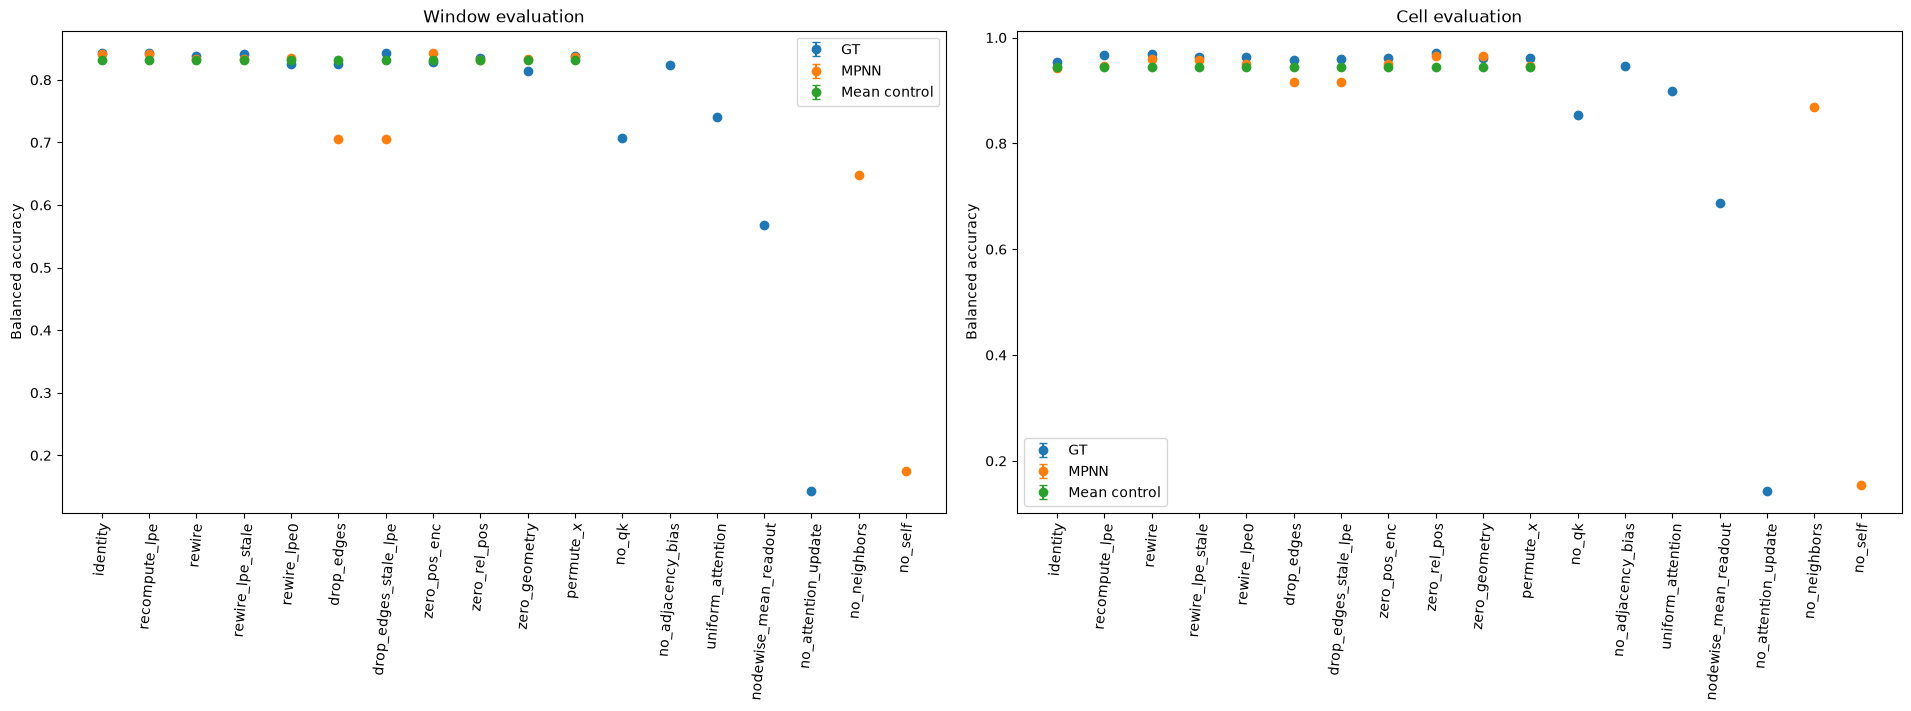

balanced_accuracy      macro_f1    
                                                      mean std      mean std
model        condition            unit                                      
GT           drop_edges           cell            0.957522 NaN  0.956908 NaN
                                  window          0.824797 NaN  0.789826 NaN
             drop_edges_stale_lpe cell            0.959404 NaN  0.961662 NaN
                                  window          0.843533 NaN  0.826411 NaN
             identity             cell            0.953193 NaN  0.958874 NaN
...                                                    ...  ..       ...  ..
Mean control zero_geometry        window          0.831514 NaN  0.820965 NaN
             zero_pos_enc         cell            0.944535 NaN  0.955513 NaN
                                  window          0.831514 NaN  0.820965 NaN
             zero_rel_pos         cell            0.944535 NaN  0.955513 NaN
                                  window          0.831514 NaN  0.820965 NaN

[80 rows x 4 columns]

In [2]:
fig,axes=plt.subplots(1,2,figsize=(19,7),constrained_layout=True)
for ax,unit in zip(axes,['window','cell']):
    subset=df[df.unit==unit]
    for model,color in zip(['GT','MPNN','Mean control'],['C0','C1','C2']):
        values=subset[subset.model==model].groupby('condition').balanced_accuracy.agg(['mean','std'])
        order=list(dict.fromkeys(df.condition))
        x=np.array([order.index(c) for c in values.index])
        ax.errorbar(x,values['mean'],yerr=values['std'].fillna(0),fmt='o',label=model,color=color,capsize=3)
    ax.set(xticks=range(len(order)),xticklabels=order,ylabel='Balanced accuracy',title=f'{unit.capitalize()} evaluation')
    ax.tick_params(axis='x',rotation=85);ax.legend()
plt.show()
display(df.groupby(['model','condition','unit'])[['balanced_accuracy','macro_f1']].agg(['mean','std']))

## Attention allocation and MPNN branch contributions
Activation statistics use a fixed class-stratified sample of up to 20,000 windows per supported class. They are descriptive of that sample, not weighted estimates over every test window. CLS and ordinary-node queries are analyzed separately. Self, graph neighbors, other nodes, and CLS partition ordinary-node attention mass.

Centered logit RMS compares QK and adjacency contributions after learned gamma scaling; comparing gamma alone would ignore the different input scales. MPNN norm fractions compare outputs of the shared neighbor and self transforms before normalization, nonlinearity, and residual addition. These are not independent fractions of prediction importance.

astrocyte                20000
microglia                 3318
oligo                        0
putative_cge             20000
putative_parvalbumin     20000
putative_somatostatin    20000
pyramidal                20000
thalamocortical          20000
Name: Sample windows, dtype: int64

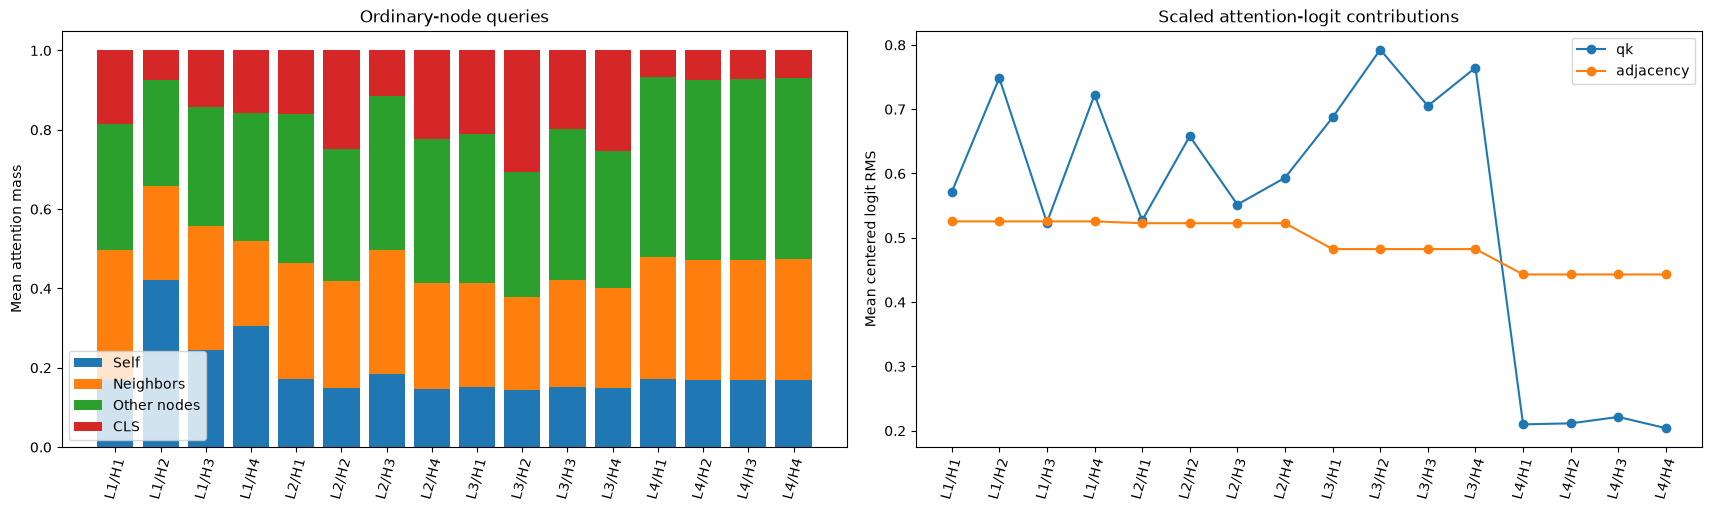

In [3]:
weight=json.loads((base/'cache/weight_analysis.json').read_text())
assert weight['plan_sha256']==results[0]['plan_sha256']
stats=weight['activation_statistics']
display(pd.Series(weight['sample_class_counts'],index=weight['classes'],name='Sample windows'))
gt=stats['GT']
labels=[f'L{l+1}/H{h+1}' for l in range(4) for h in range(4)]
fig,axes=plt.subplots(1,2,figsize=(17,5),constrained_layout=True)
bottom=np.zeros(16)
for key,label in [('self_mass','Self'),('neighbor_mass','Neighbors'),('other_node_mass','Other nodes'),('cls_key_mass','CLS')]:
    values=np.array([gt[f'GT/layer{l}/head{h}/node/{key}']['mean'] for l in range(4) for h in range(4)])
    axes[0].bar(labels,values,bottom=bottom,label=label);bottom+=values
axes[0].set(ylabel='Mean attention mass',title='Ordinary-node queries');axes[0].legend()
for term in ['qk','adjacency']:
    values=[gt[f'GT/layer{l}/head{h}/node/{term}_centered_logit_rms']['mean'] for l in range(4) for h in range(4)]
    axes[1].plot(labels,values,'o-',label=term)
axes[1].set(ylabel='Mean centered logit RMS',title='Scaled attention-logit contributions');axes[1].legend()
for ax in axes:ax.tick_params(axis='x',rotation=75)
plt.show()

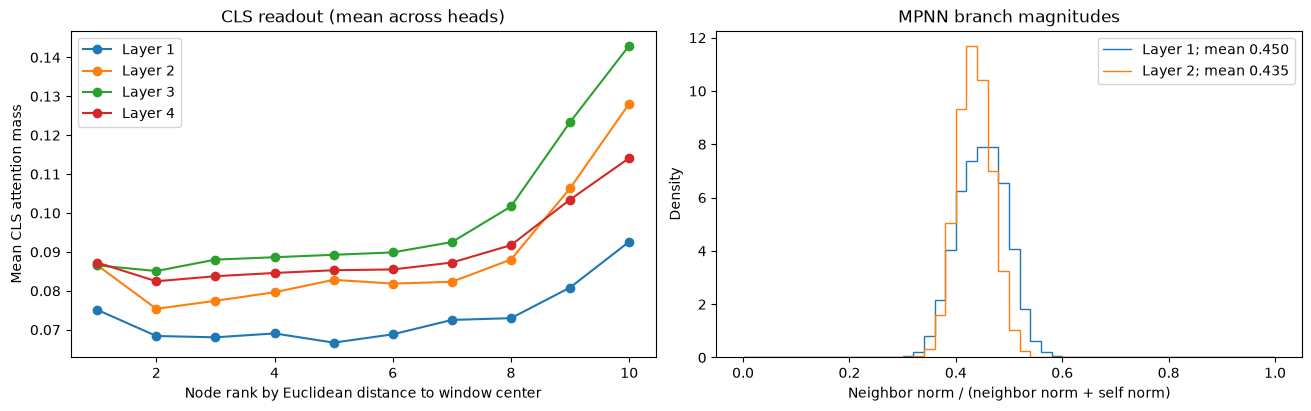

In [4]:
fig,axes=plt.subplots(1,2,figsize=(13,4),constrained_layout=True)
for l in range(4):
    values=[np.mean([gt[f'GT/layer{l}/head{h}/cls/radial_rank{rank}_mass']['mean'] for h in range(4)]) for rank in range(10)]
    axes[0].plot(range(1,11),values,'o-',label=f'Layer {l+1}')
axes[0].set(xlabel='Node rank by Euclidean distance to window center',ylabel='Mean CLS attention mass',title='CLS readout (mean across heads)');axes[0].legend()
for layer in range(2):
    row=stats['MPNN'][f'MPNN/layer{layer}/neighbor_norm_fraction'];hist=row['histogram']
    edges=np.array(hist['edges']);counts=np.array(hist['counts']);width=np.diff(edges)
    axes[1].stairs(counts/counts.sum()/width,edges,label=f'Layer {layer+1}; mean {row["mean"]:.3f}')
axes[1].set(xlabel='Neighbor norm / (neighbor norm + self norm)',ylabel='Density',title='MPNN branch magnitudes');axes[1].legend()
plt.show()

## Parameter magnitudes
Parameter RMS and Frobenius norms are recorded for every projection, message transform, feed-forward layer, and classification-head parameter. Dimensions and reparameterization affect these norms; they should not be used to rank the importance of the aggregator against the decoder.

In [5]:
parameters=pd.DataFrame([{'model':model,'parameter':name,**row} for model,values in weight['parameter_statistics'].items() for name,row in values.items()])
display(parameters)


,model,parameter,shape,parameters,rms,frobenius_norm
0,GT,graph_transformer.cls_token,"[1, 1, 128]",128,1.024855,11.594913
1,GT,graph_transformer.cls_pos_embedding,"[1, 1, 128]",128,0.813661,9.205522
2,GT,graph_transformer.to_node_embedding.0.weight,"[256, 68]",17408,0.070837,9.346133
3,GT,graph_transformer.to_node_embedding.0.bias,[256],256,0.069391,1.110254
4,GT,graph_transformer.to_node_embedding.2.weight,"[128, 256]",32768,0.037799,6.842386
...,...,...,...,...,...,...
153,Mean control,cls_head.heads.2.bias,[2],2,0.050872,0.071944
154,Mean control,cls_head.heads.3.weight,"[3, 128]",384,0.094638,1.854523
155,Mean control,cls_head.heads.3.bias,[3],3,0.035092,0.060781
156,Mean control,cls_head.heads.4.weight,"[3, 128]",384,0.085605,1.677500
